## Workshop -1 Adding Sunglasses to Your Passport Photo Using OpenCV Completion requirements


## NAME:ABHINAV GURU R

## REG.NO:212225040009

In [1]:
# Import libraries
import cv2
import numpy as np
import matplotlib.pyplot as plt

Text(0.5, 1.0, 'Face')

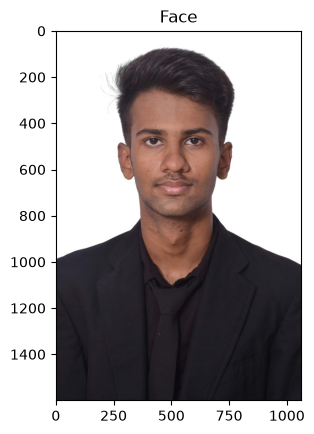

In [12]:
# Load the Face Image
faceImage = cv2.imread('abi.jpeg')
plt.imshow(faceImage[:,:,::-1]);plt.title("Face")


In [13]:
faceImage.shape

(1600, 1062, 3)

In [14]:
#resized_faceImage.shape
faceImage.shape

(1600, 1062, 3)

Text(0.5, 1.0, 'glassPNG')

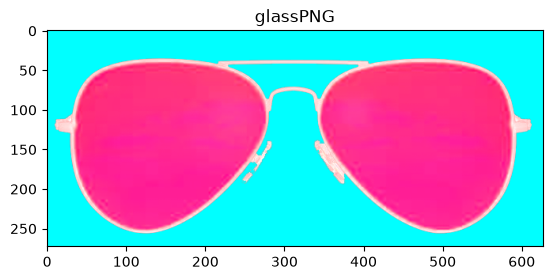

In [21]:
# Load the Sunglass image with Alpha channel
# (http://pluspng.com/sunglass-png-1104.html)
glassPNG = cv2.imread('sunglass.png',-1)
plt.imshow(glassPNG[:,:,::-1]);plt.title("glassPNG")

In [22]:
# Resize the image to fit over the eye region
# Resize sunglasses to match the width of both eyes
glassPNG = cv2.resize(glassPNG, (420, 177))
print("Sunglasses dimensions:", glassPNG.shape)

Sunglasses dimensions: (177, 420, 4)


In [23]:
# Separate the Color and alpha channels
glassBGR = glassPNG[:,:,0:3]
glassMask1 = glassPNG[:,:,3]

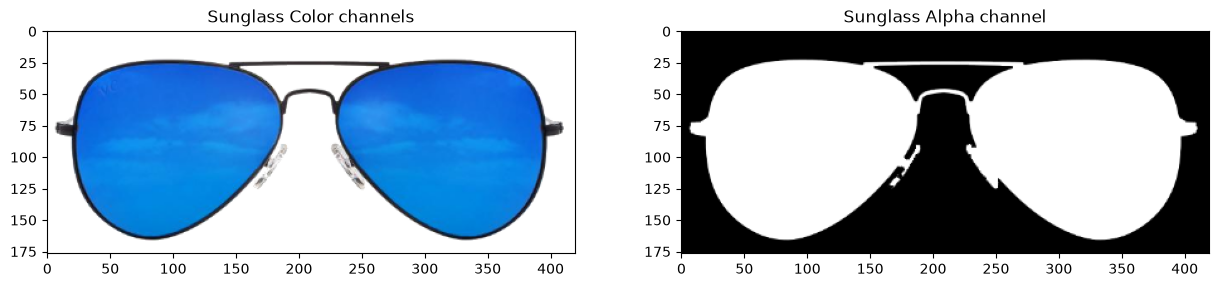

In [24]:
# Display the images for clarity
plt.figure(figsize=[15,15])
plt.subplot(121);plt.imshow(glassBGR[:,:,::-1]);plt.title('Sunglass Color channels');
plt.subplot(122);plt.imshow(glassMask1,cmap='gray');plt.title('Sunglass Alpha channel');

(np.float64(-0.5), np.float64(1061.5), np.float64(1599.5), np.float64(-0.5))

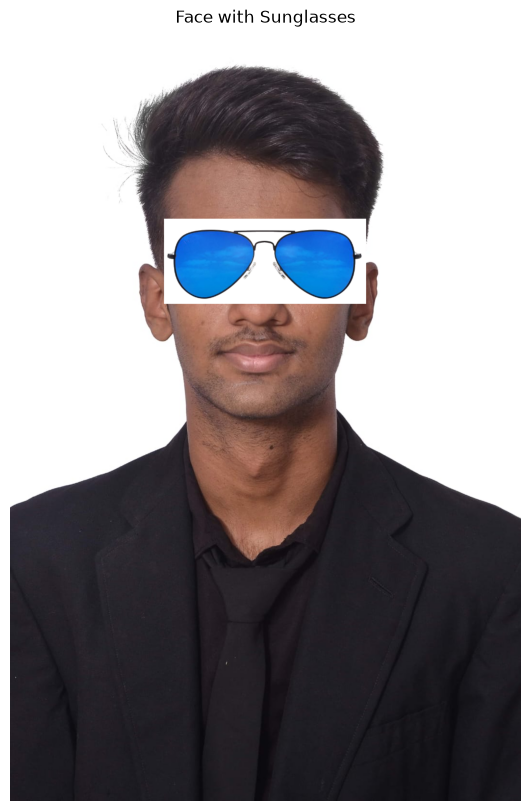

In [25]:
# Make a copy of the original face image
faceWithGlassesNaive = faceImage.copy()

# Get the dimensions of the sunglasses
glassHeight, glassWidth = glassPNG.shape[:2]

# Set the position of sunglasses on the face
x = 320
y = 390

# Place the sunglasses over the eye region
faceWithGlassesNaive[y:y+glassHeight,
                     x:x+glassWidth] = glassPNG[:, :, :3]

# Display the result
plt.figure(figsize=(8,10))
plt.imshow(faceWithGlassesNaive[:,:,::-1])
plt.title("Face with Sunglasses")
plt.axis("off")

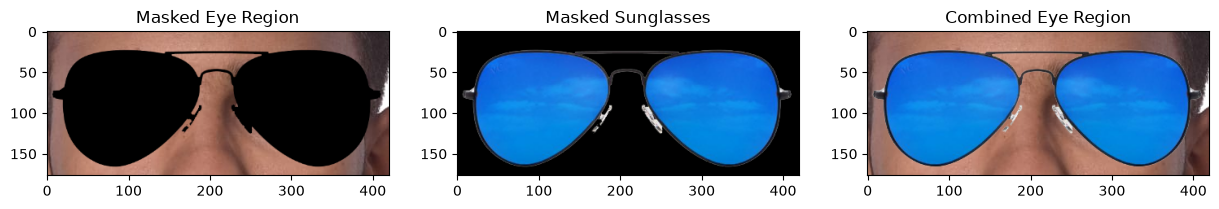

In [26]:
# Separate the RGB and alpha channels
glassBGR = glassPNG[:, :, :3]
glassMask = glassPNG[:, :, 3]

# Normalize alpha mask between 0 and 1
glassMask = glassMask.astype(np.float32) / 255.0

# Convert the mask to 3 channels
glassMask = cv2.merge((glassMask, glassMask, glassMask))

# Make a copy of the original face
faceWithGlassesArithmetic = faceImage.copy()

# Extract the eye region
eyeROI = faceWithGlassesArithmetic[
    y:y+glassHeight,
    x:x+glassWidth
]

# Create the masked eye region
maskedEye = cv2.multiply(
    eyeROI.astype(np.float32),
    1 - glassMask
)

# Create the masked sunglasses region
maskedGlass = cv2.multiply(
    glassBGR.astype(np.float32),
    glassMask
)

# Combine the eye region and sunglasses
eyeROIFinal = cv2.add(maskedEye, maskedGlass)

# Convert back to uint8
eyeROIFinal = np.uint8(eyeROIFinal)

# Display intermediate results
plt.figure(figsize=(15,5))

plt.subplot(131)
plt.imshow(maskedEye.astype(np.uint8)[:,:,::-1])
plt.title("Masked Eye Region")

plt.subplot(132)
plt.imshow(maskedGlass.astype(np.uint8)[:,:,::-1])
plt.title("Masked Sunglasses")

plt.subplot(133)
plt.imshow(eyeROIFinal[:,:,::-1])
plt.title("Combined Eye Region")

plt.show()

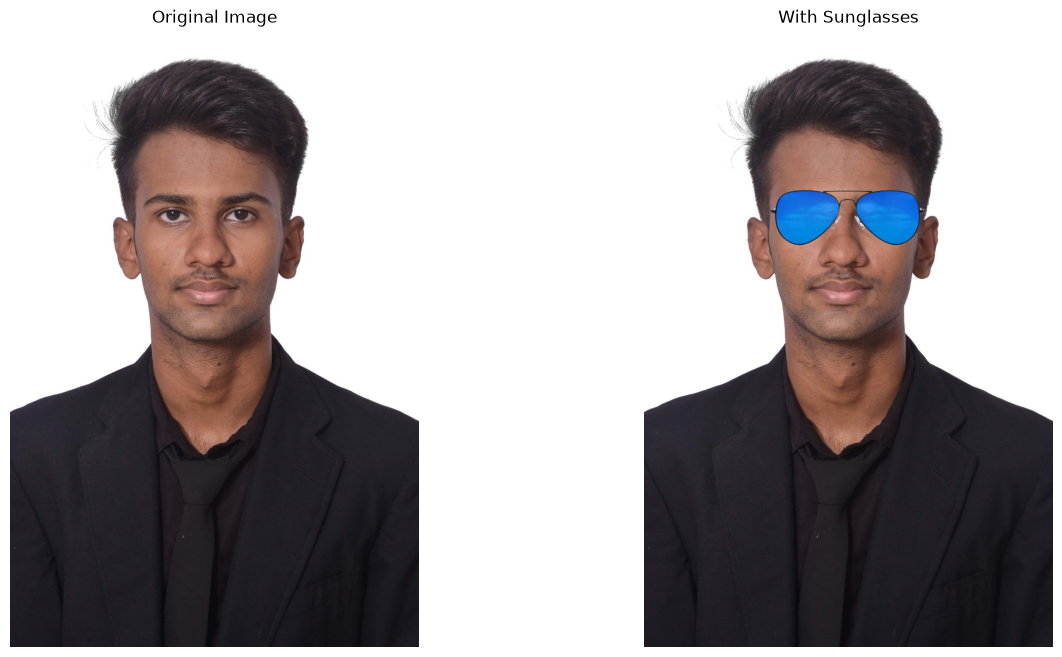

In [27]:
# Replace the eye region with the blended sunglasses
faceWithGlassesArithmetic[
    y:y+glassHeight,
    x:x+glassWidth
] = eyeROIFinal

# Display original and final images
plt.figure(figsize=(15,8))

plt.subplot(121)
plt.imshow(faceImage[:,:,::-1])
plt.title("Original Image")
plt.axis("off")

plt.subplot(122)
plt.imshow(faceWithGlassesArithmetic[:,:,::-1])
plt.title("With Sunglasses")
plt.axis("off")

plt.show()